# Recomendador de Ferramentas de IA
 
**Aplicação:** https://recomendador-ferramentas-ia-poedu7nobgs6zvtnjdytpb.streamlit.app/
Os modelos avaliados são **ranking por regras ponderadas** e **similaridade de cosseno**, ambos baseados em conteúdo; não há treinamento supervisionado nem KNN treinado. Os rótulos de relevância são preliminares.

## FASE 1: Business Understanding
### 1.1 Problema, público e decisão
Usuários frequentes de IA precisam escolher ferramentas para estudar, pesquisar, escrever, traduzir, analisar dados e criar apresentações. A hipótese de negócio é que a escolha sem apoio consome tempo, exige tentativas repetidas e pode produzir resultados inadequados. **Isso é uma hipótese a testar**, não um resultado já demonstrado.

**Público inicial:** estudantes, estagiários e profissionais. A persona do Canvas é Laura, 22 anos, universitária e estagiária. **Pergunta de negócio:** como reduzir o tempo de escolha de uma IA, considerando tarefa e restrições do usuário, sem prejudicar a qualidade?

**Produto proposto:** o usuário informa a tarefa e restrições (idioma, formato, orçamento, urgência e privacidade); o sistema sugere até três opções elegíveis, com justificativas e indicação de informações ainda não verificadas. A decisão final continua com o usuário.

## 2. Data Understanding

**Reprodutibilidade:** mantenha os arquivos CSV na mesma pasta deste notebook, ou na pasta Downloads. A base original é `genai_tools_platforms_2025.csv`. O conjunto enriquecido e os julgamentos usados na avaliação devem ser incluídos no GitHub para reprodução.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import seaborn as sns
except ImportError:
    sns = None

PASTAS = [Path.cwd(), Path.home() / "Downloads"]
def localizar(nome):
    for pasta in PASTAS:
        caminho = pasta / nome
        if caminho.is_file():
            return caminho
    raise FileNotFoundError(f"Arquivo {nome} não encontrado. Coloque-o ao lado do notebook ou em Downloads.")

arquivo_origem = localizar("genai_tools_platforms_2025.csv")
df = pd.read_csv(arquivo_origem)
print("Origem:", arquivo_origem)
print("Dimensões:", df.shape)
display(df.head())

Origem: C:\Users\crist\Downloads\ciencia_trabalho_final\genai_tools_platforms_2025.csv
Dimensões: (113, 22)


,tool_name,company,category_canonical,modality_canonical,open_source,api_available,api_status,website,source_domain,release_year,...,mod_image,mod_video,mod_audio,mod_code,mod_design,mod_infra,mod_productivity,mod_safety,mod_multimodal,modality_count
0,ChatGPT,OpenAI,LLMs & Chat Assistants,multimodal,0,1,api,https://chatgpt.com,chatgpt.com,2022,...,0,0,0,0,0,0,0,0,1,0
1,Claude,Anthropic,LLMs & Chat Assistants,multimodal,0,1,api,https://claude.ai,claude.ai,2023,...,0,0,0,0,0,0,0,0,1,0
2,Gemini,Google,LLMs & Chat Assistants,multimodal,0,1,api,https://gemini.google.com,gemini.google.com,2023,...,0,0,0,0,0,0,0,0,1,0
3,Midjourney,Midjourney,Image Gen & Editing,image,0,0,unavailable,https://www.midjourney.com,midjourney.com,2022,...,1,0,0,0,0,0,0,0,0,1
4,Stable Diffusion,Stability AI,Image Gen & Editing,image,1,1,api,https://stability.ai/stable-image,stability.ai,2022,...,1,0,0,0,0,0,0,0,0,1


**Interpretação esperada:** 113 registros e 22 colunas na versão usada pelo grupo. `head()` mostra uma amostra, não permite concluir a representatividade do mercado.

### 2.2 Estrutura, tipos e valores ausentes

In [2]:
print('Dimensões:', df.shape)
print('Tipos de dados:')
print(df.dtypes)
print('\nValores ausentes por coluna:')
print(df.isna().sum().sort_values(ascending=False))
print('\nResumo numérico e categórico:')
display(df.describe(include='all').T)

Dimensões: (113, 22)
Tipos de dados:
tool_name                str
company                  str
category_canonical       str
modality_canonical       str
open_source            int64
api_available          int64
api_status               str
website                  str
source_domain            str
release_year           int64
years_since_release    int64
mod_text               int64
mod_image              int64
mod_video              int64
mod_audio              int64
mod_code               int64
mod_design             int64
mod_infra              int64
mod_productivity       int64
mod_safety             int64
mod_multimodal         int64
modality_count         int64
dtype: object

Valores ausentes por coluna:
tool_name              0
company                0
category_canonical     0
modality_canonical     0
open_source            0
api_available          0
api_status             0
website                0
source_domain          0
release_year           0
years_since_release    0
mod_te

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tool_name,113,113,ChatGPT,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company,113,83,OpenAI,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_canonical,113,13,LLMs & Chat Assistants,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modality_canonical,113,10,multimodal,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
open_source,113.0,NaN,NaN,NaN,0.371681,0.485406,0.0,0.0,0.0,1.0,1.0
api_available,113.0,NaN,NaN,NaN,0.946903,0.225226,0.0,1.0,1.0,1.0,1.0
api_status,113,2,api,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN
website,113,105,https://platform.openai.com,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_domain,113,88,github.com,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,113.0,NaN,NaN,NaN,2022.20354,2.083778,2013.0,2022.0,2023.0,2023.0,2025.0


### 2.3 Duplicatas, domínios e valores inválidos
Verificamos duplicatas de linhas e nomes, indicadores fora de 0/1, anos fora de um intervalo plausível e coerência entre `api_available` e `api_status`. Não removemos dados automaticamente: primeiro diagnosticamos.

In [3]:
print('Linhas duplicadas:', int(df.duplicated().sum()))
print('Nomes duplicados:', int(df['tool_name'].duplicated().sum()))
print('Nomes distintos:', df['tool_name'].nunique())
flags = ['open_source','api_available'] + [c for c in df if c.startswith('mod_')]
for col in flags:
    invalidos = (~df[col].isin([0,1])) & df[col].notna()
    print(f'{col}: {int(invalidos.sum())} valores fora de 0/1')
print('Ano mínimo e máximo:', df['release_year'].min(), df['release_year'].max())
print('Anos fora de 1990–2025:', int((~df['release_year'].between(1990,2025)).sum()))
print('Status de API:', df['api_status'].value_counts(dropna=False).to_dict())
display(pd.crosstab(df['api_available'], df['api_status'], dropna=False))

Linhas duplicadas: 0
Nomes duplicados: 0
Nomes distintos: 113
open_source: 0 valores fora de 0/1
api_available: 0 valores fora de 0/1
mod_text: 0 valores fora de 0/1
mod_image: 0 valores fora de 0/1
mod_video: 0 valores fora de 0/1
mod_audio: 0 valores fora de 0/1
mod_code: 0 valores fora de 0/1
mod_design: 0 valores fora de 0/1
mod_infra: 0 valores fora de 0/1
mod_productivity: 0 valores fora de 0/1
mod_safety: 0 valores fora de 0/1
mod_multimodal: 0 valores fora de 0/1
Ano mínimo e máximo: 2013 2025
Anos fora de 1990–2025: 0
Status de API: {'api': 107, 'unavailable': 6}


api_status,api,unavailable
api_available,,
0,0,6
1,107,0


### 2.4 Consistência entre modalidades e contagem
No resumo inicial, `modality_count` variou de 0 a 1, embora o nome sugira uma contagem. Compararemos com a soma das flags para identificar divergências, **sem sobrescrever o dado original**.

In [4]:
colunas_mod = [c for c in df.columns if c.startswith('mod_')]
diagnostico_modalidades = df[['tool_name','modality_canonical','modality_count']].copy()
diagnostico_modalidades['soma_flags'] = df[colunas_mod].sum(axis=1)
diagnostico_modalidades['diverge'] = diagnostico_modalidades['modality_count'] != diagnostico_modalidades['soma_flags']
print('Divergências entre modality_count e soma das flags:', int(diagnostico_modalidades['diverge'].sum()))
display(diagnostico_modalidades.loc[diagnostico_modalidades['diverge']].head(15))
print('Distribuição da soma das flags:')
display(diagnostico_modalidades['soma_flags'].value_counts().sort_index())

Divergências entre modality_count e soma das flags: 55


,tool_name,modality_canonical,modality_count,soma_flags,diverge
0,ChatGPT,multimodal,0,1,True
1,Claude,multimodal,0,1,True
2,Gemini,multimodal,0,1,True
16,Perplexity,multimodal,0,1,True
17,Meta AI,multimodal,0,1,True
18,Mistral Le Chat,multimodal,0,1,True
19,Pinecone,infra,0,1,True
20,Weaviate,infra,0,1,True
21,Milvus,infra,0,1,True
22,Qdrant,infra,0,1,True


Distribuição da soma das flags:


soma_flags
1    113
Name: count, dtype: int64

### 2.5 Análise exploratória
Gráficos para observar **categorias, modalidades e restrições técnicas**, e não sobrevivência.

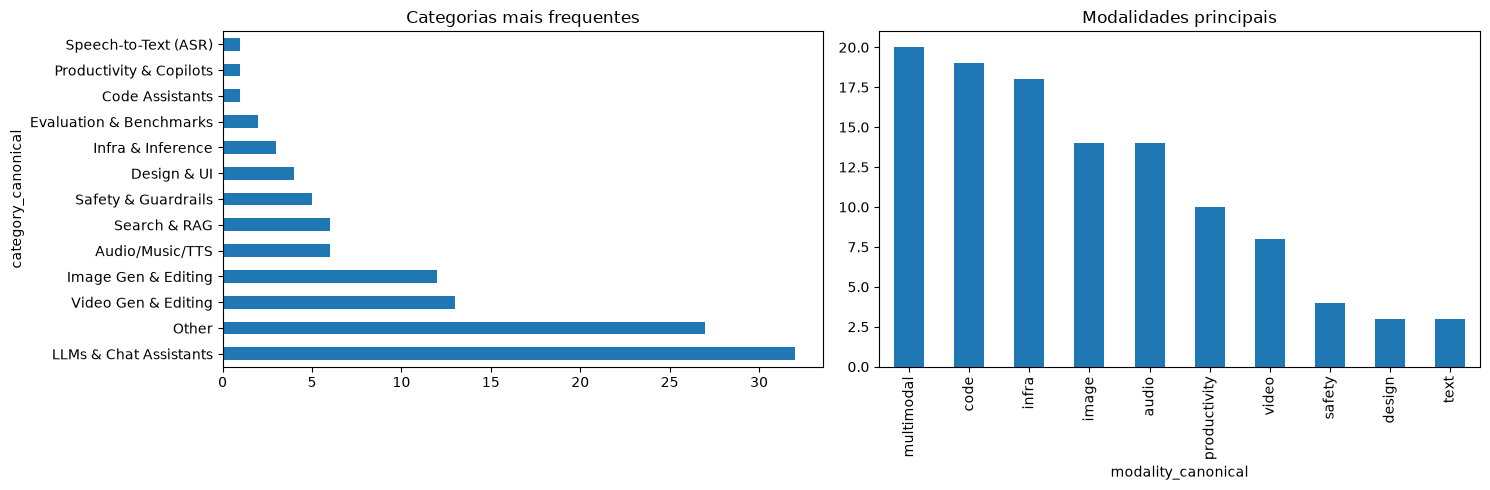

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df["category_canonical"].value_counts().head(15).plot.barh(ax=axes[0], title="Categorias mais frequentes")
df["modality_canonical"].value_counts().plot.bar(ax=axes[1], title="Modalidades principais")
plt.tight_layout(); plt.show()

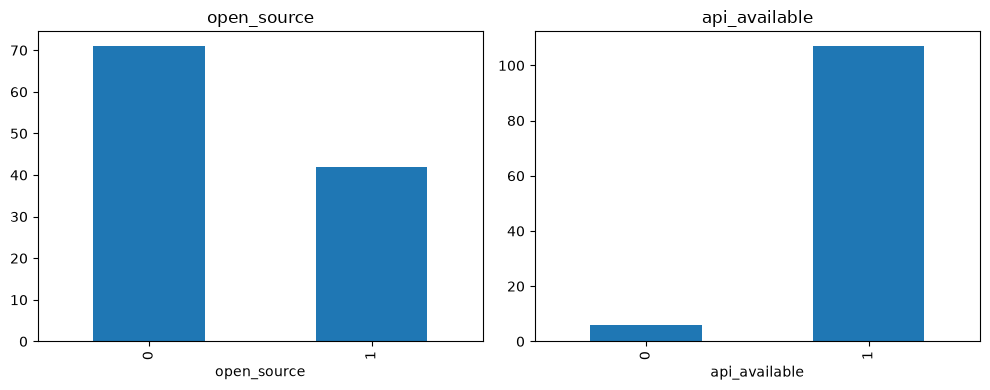

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, coluna in zip(axes, ["open_source", "api_available"]):
    df[coluna].value_counts(dropna=False).sort_index().plot.bar(ax=ax, title=coluna)
plt.tight_layout(); plt.show()

,open_source=0,open_source=1
category_canonical,,
Audio/Music/TTS,4,2
Code Assistants,1,0
Design & UI,4,0
Evaluation & Benchmarks,1,1
Image Gen & Editing,8,4
Infra & Inference,2,1
LLMs & Chat Assistants,18,14
Other,18,9
Productivity & Copilots,1,0


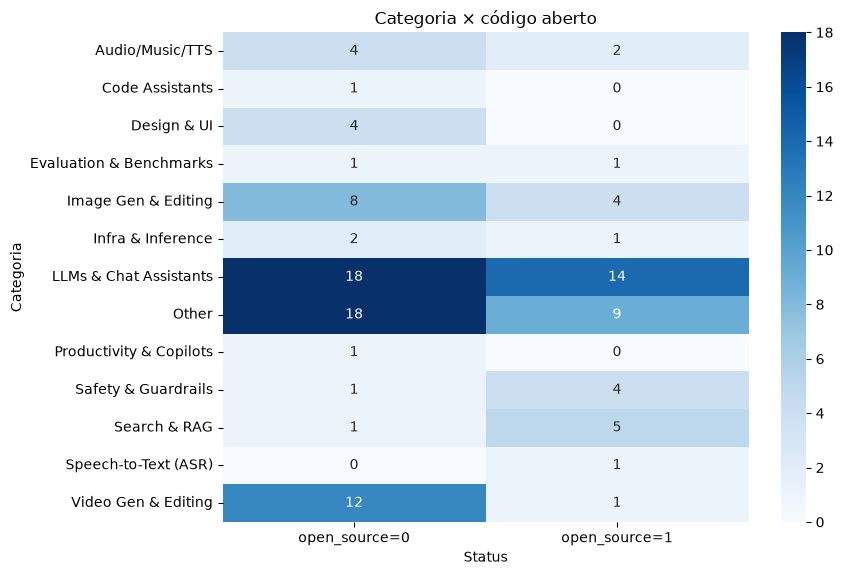

api_available,0,1
modality_canonical,,
audio,0,14
code,0,19
design,0,3
image,4,10
infra,1,17
multimodal,0,20
productivity,0,10
safety,0,4
text,0,3


In [7]:
tabela = pd.crosstab(df['category_canonical'], df['open_source'])
tabela.columns = [f'open_source={c}' for c in tabela.columns]
display(tabela)
fig, ax = plt.subplots(figsize=(9, max(5, len(tabela)*0.45)))
sns.heatmap(tabela, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set(title='Categoria × código aberto', xlabel='Status', ylabel='Categoria')
plt.tight_layout()
plt.show()
display(pd.crosstab(df['modality_canonical'], df['api_available']))

**Interpretação:** as colunas `mod_*` representam a modalidade principal cadastrada, não todas as capacidades de cada ferramenta. O catálogo não oferece avaliações independentes por tarefa nem informações completas de preço e desempenho.

## 3. Data Preparation

Selecionamos atributos de identificação, categoria, modalidade e restrições técnicas. O enriquecimento funcional foi feito em arquivo separado, com capacidades verificadas apenas para parte das ferramentas de programação; valores ausentes não devem ser interpretados como ausência da capacidade.

In [8]:
colunas_modelagem = ["tool_name", "company", "category_canonical", "modality_canonical", "open_source", "api_available", "website"]
df_modelagem = df[colunas_modelagem].copy()
for coluna in ["open_source", "api_available"]:
    df_modelagem[coluna] = pd.to_numeric(df_modelagem[coluna], errors="coerce")
assert df_modelagem["tool_name"].notna().all()
assert not df_modelagem["tool_name"].duplicated().any(), "Verifique nomes duplicados antes de modelar"
print("Base de modelagem:", df_modelagem.shape)
display(df_modelagem.head())

try:
    df_enriquecida = pd.read_csv(localizar("ferramentas_ia_enriquecida.csv"))
    print("Base enriquecida:", df_enriquecida.shape)
except FileNotFoundError:
    df_enriquecida = df_modelagem.copy()
    print("Base enriquecida não encontrada; usando apenas a base original.")

Base de modelagem: (113, 7)


,tool_name,company,category_canonical,modality_canonical,open_source,api_available,website
0,ChatGPT,OpenAI,LLMs & Chat Assistants,multimodal,0,1,https://chatgpt.com
1,Claude,Anthropic,LLMs & Chat Assistants,multimodal,0,1,https://claude.ai
2,Gemini,Google,LLMs & Chat Assistants,multimodal,0,1,https://gemini.google.com
3,Midjourney,Midjourney,Image Gen & Editing,image,0,0,https://www.midjourney.com
4,Stable Diffusion,Stability AI,Image Gen & Editing,image,1,1,https://stability.ai/stable-image


Base enriquecida: (113, 15)


## 4. Modelagem — dois métodos baseados em conteúdo

O ranking ponderado atribui 3 pontos à correspondência de modalidade principal e 2 à categoria. O segundo modelo usa similaridade de cosseno em uma codificação one-hot das mesmas características. A preferência por API ou código aberto é tratada como filtro obrigatório. Empates são resolvidos alfabeticamente, o que limita a diversidade dos resultados.

In [9]:
def recomendar_ranking(
    df,
    modalidades,
    categoria=None,
    exige_api=False,
    exige_open_source=False,
    top_n=10
):
    modalidades = list(dict.fromkeys(modalidades))

    if not modalidades and not categoria:
        raise ValueError(
            "Selecione pelo menos uma modalidade ou categoria."
        )

    candidatos = df.copy()

    if exige_api:
        candidatos = candidatos[
            candidatos["api_available"] == 1
        ].copy()

    if exige_open_source:
        candidatos = candidatos[
            candidatos["open_source"] == 1
        ].copy()

    if candidatos.empty:
        return pd.DataFrame()

    candidatos["modalidades_atendidas"] = (
        candidatos["modality_canonical"]
        .isin(modalidades)
        .astype(int)
    )

    if categoria:
        candidatos["match_categoria"] = (
            candidatos["category_canonical"] == categoria
        ).astype(int)
    else:
        candidatos["match_categoria"] = 0

    peso_modalidade = 3
    peso_categoria = 2

    pontos_possiveis = (
        len(modalidades) * peso_modalidade
        + (peso_categoria if categoria else 0)
    )

    candidatos["score"] = (
        candidatos["modalidades_atendidas"] * peso_modalidade
        + candidatos["match_categoria"] * peso_categoria
    )

    candidatos["compatibilidade_%"] = (
        100 * candidatos["score"] / pontos_possiveis
    ).round(1)

    candidatos = candidatos[
        candidatos["score"] > 0
    ].copy()

    candidatos = candidatos.sort_values(
        ["score", "tool_name"],
            ascending=[False, True]
    )

    return candidatos[
        [
            "tool_name",
            "company",
            "category_canonical",
            "modality_canonical",
            "modalidades_atendidas",
            "match_categoria",
            "compatibilidade_%",
            "website"
        ]
    ].head(top_n).reset_index(drop=True)

In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

def recomendar_cosseno(
    df,
    modalidades,
    categoria=None,
    exige_api=False,
    exige_open_source=False,
    top_n=10
):
    modalidades = list(dict.fromkeys(modalidades))

    if not modalidades and not categoria:
        raise ValueError(
            "Selecione pelo menos uma modalidade ou categoria."
        )

    candidatos = df.copy()

    # Mesmos filtros obrigatórios do Modelo A
    if exige_api:
        candidatos = candidatos[
            candidatos["api_available"] == 1
        ].copy()

    if exige_open_source:
        candidatos = candidatos[
            candidatos["open_source"] == 1
        ].copy()

    if candidatos.empty:
        return pd.DataFrame()

    # Representação binária das modalidades
    todas_modalidades = sorted(
        df["modality_canonical"].unique()
    )

    matriz_modalidades = pd.get_dummies(
        candidatos["modality_canonical"]
    ).reindex(
        columns=todas_modalidades,
        fill_value=0
    ).astype(float)

    vetor_usuario = np.array([
        1.0 if m in modalidades else 0.0
        for m in todas_modalidades
    ])

    # Categoria opcional, com peso relativo de 2
    if categoria:
        todas_categorias = sorted(
            df["category_canonical"].unique()
        )

        matriz_categorias = pd.get_dummies(
            candidatos["category_canonical"]
        ).reindex(
            columns=todas_categorias,
            fill_value=0
        ).astype(float)

        matriz = np.column_stack([
            matriz_modalidades.values * np.sqrt(3),
            matriz_categorias.values * np.sqrt(2)
        ])

        vetor_categoria = np.array([
            1.0 if c == categoria else 0.0
            for c in todas_categorias
        ])

        perfil = np.concatenate([
            vetor_usuario * np.sqrt(3),
            vetor_categoria * np.sqrt(2)
        ])

    else:
        matriz = matriz_modalidades.values
        perfil = vetor_usuario

    similaridades = cosine_similarity(
        matriz,
        perfil.reshape(1, -1)
    ).flatten()

    candidatos["similaridade_%"] = (
        similaridades * 100
    ).round(1)

    candidatos = candidatos[
        candidatos["similaridade_%"] > 0
    ].copy()

    candidatos = candidatos.sort_values(
        ["similaridade_%", "tool_name"],
        ascending=[False, True]
    )

    return candidatos[
        [
            "tool_name",
            "company",
            "category_canonical",
            "modality_canonical",
            "similaridade_%",
            "website"
        ]
    ].head(top_n).reset_index(drop=True)

In [11]:
exemplo_a = recomendar_ranking(df_modelagem, modalidades=["code"], top_n=5)
exemplo_b = recomendar_cosseno(df_modelagem, modalidades=["code"], top_n=5)
print("Ranking ponderado:"); display(exemplo_a)
print("Similaridade de cosseno:"); display(exemplo_b)

Ranking ponderado:


,tool_name,company,category_canonical,modality_canonical,modalidades_atendidas,match_categoria,compatibilidade_%,website
0,Amazon Q Developer,Amazon Web Services,LLMs & Chat Assistants,code,1,0,100.0,https://aws.amazon.com/q/developer/
1,Anthropic Tool Use,Anthropic,Other,code,1,0,100.0,https://docs.anthropic.com
2,Blackbox AI,Blackbox,LLMs & Chat Assistants,code,1,0,100.0,https://www.useblackbox.io
3,Code Llama,Meta,LLMs & Chat Assistants,code,1,0,100.0,https://ai.meta.com/llama/
4,Codeium,Codeium (Qodo),LLMs & Chat Assistants,code,1,0,100.0,https://www.codeium.com


Similaridade de cosseno:


,tool_name,company,category_canonical,modality_canonical,similaridade_%,website
0,Amazon Q Developer,Amazon Web Services,LLMs & Chat Assistants,code,100.0,https://aws.amazon.com/q/developer/
1,Anthropic Tool Use,Anthropic,Other,code,100.0,https://docs.anthropic.com
2,Blackbox AI,Blackbox,LLMs & Chat Assistants,code,100.0,https://www.useblackbox.io
3,Code Llama,Meta,LLMs & Chat Assistants,code,100.0,https://ai.meta.com/llama/
4,Codeium,Codeium (Qodo),LLMs & Chat Assistants,code,100.0,https://www.codeium.com


## 5. Avaliação

As 12 consultas representam necessidades de programação, imagem, vídeo, áudio, conversação, RAG, design e segurança. Cada modelo recomenda até 5 ferramentas. O arquivo `avaliacao_top5.csv` contém 59 pares únicos julgados preliminarmente (54 positivos, 5 negativos). Parte desses julgamentos foi atribuída por compatibilidade funcional geral, sem validação independente de todas as capacidades. A métrica, portanto, é **exploratória** e não deve ser interpretada como desempenho generalizável.

In [12]:
consultas = [
    ("Q01", "Assistente para escrever código", "code", None),
    ("Q02", "Ferramenta para depurar código", "code", None),
    ("Q03", "Gerar imagens com IA", "image", "Image Gen & Editing"),
    ("Q04", "Editar imagens com IA", "image", "Image Gen & Editing"),
    ("Q05", "Gerar vídeos com IA", "video", "Video Gen & Editing"),
    ("Q06", "Editar vídeos com IA", "video", "Video Gen & Editing"),
    ("Q07", "Transcrever áudio em texto", "audio", "Speech-to-Text (ASR)"),
    ("Q08", "Gerar áudio ou voz", "audio", "Audio/Music/TTS"),
    ("Q09", "Assistente de conversação", "multimodal", "LLMs & Chat Assistants"),
    ("Q10", "Pesquisar documentos com RAG", "infra", "Search & RAG"),
    ("Q11", "Criar interfaces e designs", "design", "Design & UI"),
    ("Q12", "Avaliar segurança de IA", "safety", "Safety & Guardrails"),
]
df_consultas = pd.DataFrame(consultas, columns=["consulta_id", "necessidade", "modalidade", "categoria"])
display(df_consultas)

,consulta_id,necessidade,modalidade,categoria
0,Q01,Assistente para escrever código,code,NaN
1,Q02,Ferramenta para depurar código,code,NaN
2,Q03,Gerar imagens com IA,image,Image Gen & Editing
3,Q04,Editar imagens com IA,image,Image Gen & Editing
4,Q05,Gerar vídeos com IA,video,Video Gen & Editing
5,Q06,Editar vídeos com IA,video,Video Gen & Editing
6,Q07,Transcrever áudio em texto,audio,Speech-to-Text (ASR)
7,Q08,Gerar áudio ou voz,audio,Audio/Music/TTS
8,Q09,Assistente de conversação,multimodal,LLMs & Chat Assistants
9,Q10,Pesquisar documentos com RAG,infra,Search & RAG


In [13]:
resultados = []
for _, consulta in df_consultas.iterrows():
    categoria = None if pd.isna(consulta["categoria"]) else consulta["categoria"]
    for modelo, funcao in [("Ranking ponderado", recomendar_ranking), ("Similaridade de cosseno", recomendar_cosseno)]:
        recomendacoes = funcao(df_enriquecida, modalidades=[consulta["modalidade"]], categoria=categoria, top_n=5)
        for posicao, (_, ferramenta) in enumerate(recomendacoes.iterrows(), start=1):
            resultados.append({"consulta_id": consulta["consulta_id"], "necessidade": consulta["necessidade"], "modelo": modelo, "posicao": posicao, "tool_name": ferramenta["tool_name"]})
df_resultados = pd.DataFrame(resultados)
print("Recomendações geradas:", len(df_resultados))
display(df_resultados.head(10))

Recomendações geradas: 118


,consulta_id,necessidade,modelo,posicao,tool_name
0,Q01,Assistente para escrever código,Ranking ponderado,1,Amazon Q Developer
1,Q01,Assistente para escrever código,Ranking ponderado,2,Anthropic Tool Use
2,Q01,Assistente para escrever código,Ranking ponderado,3,Blackbox AI
3,Q01,Assistente para escrever código,Ranking ponderado,4,Code Llama
4,Q01,Assistente para escrever código,Ranking ponderado,5,Codeium
5,Q01,Assistente para escrever código,Similaridade de cosseno,1,Amazon Q Developer
6,Q01,Assistente para escrever código,Similaridade de cosseno,2,Anthropic Tool Use
7,Q01,Assistente para escrever código,Similaridade de cosseno,3,Blackbox AI
8,Q01,Assistente para escrever código,Similaridade de cosseno,4,Code Llama
9,Q01,Assistente para escrever código,Similaridade de cosseno,5,Codeium


In [14]:
avaliacao = pd.read_csv(localizar("avaliacao_top5.csv"))
assert not avaliacao.duplicated(["consulta_id", "tool_name"]).any()
comparacao = df_resultados.merge(avaliacao[["consulta_id", "tool_name", "relevancia"]], on=["consulta_id", "tool_name"], how="left", validate="many_to_one")
assert comparacao["relevancia"].notna().all(), "Há recomendações sem rótulo; revise avaliacao_top5.csv"
metricas = (comparacao.groupby(["modelo", "consulta_id"]).agg(recomendacoes=("tool_name", "size"), relevantes=("relevancia", "sum")).reset_index())
metricas["precision_top5"] = (metricas["relevantes"] / 5).round(3)
resumo = (metricas.groupby("modelo").agg(media_precision_top5=("precision_top5", "mean"), consultas=("consulta_id", "nunique")).reset_index())
print("Precision@5 por consulta:"); display(metricas)
print("Resumo:"); display(resumo)
print("Pares únicos avaliados:", len(avaliacao), "| positivos:", int(avaliacao["relevancia"].eq(1).sum()), "| negativos:", int(avaliacao["relevancia"].eq(0).sum()))

Precision@5 por consulta:


,modelo,consulta_id,recomendacoes,relevantes,precision_top5
0,Ranking ponderado,Q01,5,4.0,0.8
1,Ranking ponderado,Q02,5,4.0,0.8
2,Ranking ponderado,Q03,5,5.0,1.0
3,Ranking ponderado,Q04,5,5.0,1.0
4,Ranking ponderado,Q05,5,5.0,1.0
5,Ranking ponderado,Q06,5,5.0,1.0
6,Ranking ponderado,Q07,5,4.0,0.8
7,Ranking ponderado,Q08,5,4.0,0.8
8,Ranking ponderado,Q09,5,5.0,1.0
9,Ranking ponderado,Q10,5,4.0,0.8


Resumo:


,modelo,media_precision_top5,consultas
0,Ranking ponderado,0.9,12
1,Similaridade de cosseno,0.9,12


Pares únicos avaliados: 59 | positivos: 54 | negativos: 5


In [15]:
comparacao_ordem = df_resultados.pivot(index=["consulta_id", "posicao"], columns="modelo", values="tool_name")
modelos = ["Ranking ponderado", "Similaridade de cosseno"]
mesma_ordem = (comparacao_ordem[modelos[0]].fillna("") == comparacao_ordem[modelos[1]].fillna("")).all()
print("Rankings idênticos nas 12 consultas:", mesma_ordem)
print("Nota: Q11 retorna quatro ferramentas, mas o denominador de Precision@5 permanece cinco.")

Rankings idênticos nas 12 consultas: True
Nota: Q11 retorna quatro ferramentas, mas o denominador de Precision@5 permanece cinco.


## 6. Resultados, limitações e conclusão

- **Resultado observado:** ambos os métodos apresentaram Precision@5 médio de **0,90** no conjunto de 12 consultas, considerando a quinta posição vazia da Q11 como não relevante.
- **Comparação:** as recomendações e sua ordenação foram idênticas nas consultas avaliadas; portanto, **não há evidência de superioridade** de um método sobre o outro.
- **Limitações:** o catálogo possui 113 ferramentas e atributos predominantemente categóricos; não contém rótulos independentes de relevância, avaliações de usuários, preços confiáveis ou cobertura detalhada de tarefas. A classificação de parte dos 59 pares foi preliminar e pode superestimar o resultado. Não foi possível estimar recall verdadeiro sem conhecer todas as ferramentas relevantes por consulta.
- **Aplicação:** o Streamlit disponibiliza filtros e explicações adicionais; o Precision@5 acima se refere aos **modelos A/B deste notebook**, não a uma avaliação independente da versão publicada.
- **Próximos passos:** ampliar a validação humana com fontes por ferramenta, adicionar atributos de tarefas específicas (gerar vs. editar), avaliar consultas novas e estudar diversificação e métricas de ranking.

**Aplicativo:** https://recomendador-ferramentas-ia-poedu7nobgs6zvtnjdytpb.streamlit.app/